# Projet 11 : Notebook d'entraînement (AI4I 2020 + RandomForest)

Ce notebook rejoue **pas à pas** ce que fait `ml/train.py`, avec les explications.
Il réutilise les mêmes fonctions : ce qu'on voit ici est exactement ce qui tourne en production.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'ml':
    os.chdir('..')            # on travaille depuis la racine du projet
sys.path.insert(0, os.getcwd())
import pandas as pd
from ml import train
from ml.features import FEATURES, to_features

## 1. Chargement des données
Téléchargement du CSV officiel (UCI). Sans Internet, un générateur synthétique produit les mêmes colonnes.

In [2]:
raw, source = train.load_data()
print(source, raw.shape)
raw.head()

AI4I 2020 (UCI) (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Exploration rapide
Le point clé : **seulement ~3,4 % de pannes**. C'est un problème déséquilibré.

In [3]:
print(raw['Machine failure'].value_counts())
print(f"Taux de panne : {raw['Machine failure'].mean():.2%}")
raw[['TWF','HDF','PWF','OSF','RNF']].sum().rename('nb de pannes par mode')

Machine failure
0    9661
1     339
Name: count, dtype: int64
Taux de panne : 3.39%


TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
Name: nb de pannes par mode, dtype: int64

In [4]:
raw.groupby('Machine failure')[['Air temperature [K]','Process temperature [K]',
    'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']].mean().round(1)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,300.0,310.0,1540.3,39.6,106.7
1,300.9,310.3,1496.5,50.2,143.8


Lecture : en cas de panne, le **couple** et l'**usure de l'outil** sont nettement plus élevés, et la vitesse de rotation plus basse. Ce sont nos meilleurs signaux.

## 3. Prétraitement
- renommage en noms courts (ceux des messages MQTT)
- suppression de `UDI` et `Product ID` (identifiants, sans information physique)
- suppression de `TWF, HDF, PWF, OSF, RNF` : ce sont les **types** de panne, connus *après* la panne. Les garder = **fuite de données** (le modèle lirait la réponse).

In [5]:
df = train.preprocess(raw)
print(df.columns.tolist())
to_features(df).head()

['type', 'air_temp_k', 'process_temp_k', 'rpm', 'torque_nm', 'tool_wear_min', 'panne_reelle']


,type_code,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min
0,1.0,298.1,308.6,1551.0,42.8,0.0
1,0.0,298.2,308.7,1408.0,46.3,3.0
2,0.0,298.1,308.5,1498.0,49.4,5.0
3,0.0,298.2,308.6,1433.0,39.5,7.0
4,0.0,298.2,308.7,1408.0,40.0,9.0


## 4. Entraînement
- split **stratifié** 80/20 (même proportion de pannes dans train et test)
- `StandardScaler` appris sur le train uniquement
- `RandomForestClassifier(n_estimators=200, class_weight='balanced')` : `balanced` donne plus de poids aux rares exemples de panne

In [6]:
model, scaler, x_test, y_test, df_test = train.train(df)
print('Test :', x_test.shape)

Test : (2000, 6)


## 5. Évaluation
`panne_probable = predict_proba(...)[:, 1]`, la probabilité de la classe « panne ».

In [7]:
metrics = train.evaluate(model, scaler, x_test, y_test, source)
{k: metrics[k] for k in ['f1','precision','recall','roc_auc']}

{'f1': 0.6792, 'precision': 0.5934, 'recall': 0.7941, 'roc_auc': 0.9709}

In [8]:
pd.DataFrame([[metrics['confusion_matrix']['vrais_negatifs'], metrics['confusion_matrix']['faux_positifs']],
              [metrics['confusion_matrix']['faux_negatifs'], metrics['confusion_matrix']['vrais_positifs']]],
             index=['Réel normal','Réel panne'], columns=['Prédit normal','Prédit panne'])

,Prédit normal,Prédit panne
Réel normal,1895,37
Réel panne,14,54


**Lecture** : le rappel (recall) mesure la part des vraies pannes détectées. En maintenance, rater une panne (faux négatif) coûte plus cher qu'une fausse alerte (faux positif) : on surveille donc d'abord le rappel.

In [9]:
print('Au seuil d alarme ThingsBoard (0.7) :', metrics['au_seuil_alarme_0.7'])

Au seuil d alarme ThingsBoard (0.7) : {'precision': 0.8333, 'recall': 0.6618, 'f1': 0.7377}


Monter le seuil de 0.5 à 0.7 augmente la **précision** (moins de fausses alertes) mais baisse le **rappel**. C'est exactement le compromis réglable en direct via l'attribut partagé `threshold` dans ThingsBoard.

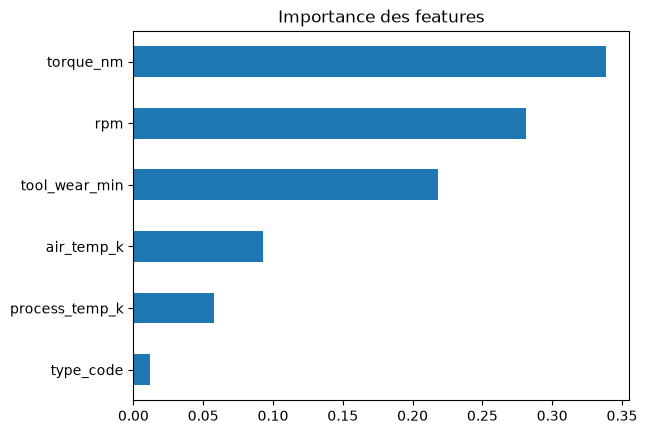

In [10]:
pd.Series(metrics['importance_features']).sort_values().plot.barh(title='Importance des features');

## 6. Exemple d'inférence (ce que fait `api.py`)

In [11]:
mesure = pd.DataFrame([{'type':'L','air_temp_k':300.0,'process_temp_k':310.0,
                        'rpm':1300,'torque_nm':65.0,'tool_wear_min':210}])
p = model.predict_proba(scaler.transform(to_features(mesure)))[0, 1]
print(f'panne_probable = {p:.3f}')

panne_probable = 0.937


Les artefacts (`model.joblib`, `scaler.joblib`, `metrics.json`, `confusion_matrix.png`) sont écrits par `python -m ml.train`.